# Librerías

In [ ]:
import numpy as np #para manejar arreglos
from matplotlib import pyplot as plt #para graficar

plt.rcParams["figure.figsize"] = (8,5) #tamaño de los gráficos: ancho x alto

import pandas as pd # para levantar datos desde archivos: txt, csv, otros.

from numpy.polynomial import Polynomial as Poly

---
# Componentes Principales

- ## Charlar la idea de componentes principales:
  - ### Direcciones con mayor varianza
  - ### Varianza como forma de medir información
  - ### Rotación ortogonal de ejes
  - ### Reducción de la dimensión
---

## Ejemplo: a partir de los datos provistos en el archivo `datos.csv` se pide:
1. ### Normalizar los datos. **De ahora en más se trabaja con los datos normalizados**
2. ### Inspeccionar la correlación de a pares de variables.
3. ### Calcular la matriz de covarianza, y hallar sus autovalores y autovectores.
4. ### Hallar las componentes principales: dar la fórmula para los scores, es decir la fórmula que permite transformar el dato original al mismo dato pero escrito en las coordenadas de los ejes dados por las componentes principales.
5. ### Hallar los scores, es decir la nueva tabla de datos correspondiente a los datos pero escritos en los nuevos ejes dados por las componentes principales.
6. ### Utilizando regresión lineal (cuadrados mínimos) decidir en cuáles de las componentes principales está mayormente representada la información de los datos.
7. ### Indicar la proporción de variabilidad explicada por cada componente principal.
8. ### Hallar la cantidad de componentes principales que explican al menos el 96% de la variabilidad acumulada.
9. ### Hallar los scores para la cantidad de componentes principales averiguadas en el ítem anterior, es decir los nuevos datos truncados provenientes de la reducción de la dimensión del ítem anterior.
10. ### Graficar los nuevos datos truncados.


1. ### Normalizar los datos. **De ahora en más se trabaja con los datos normalizados**

In [ ]:
# levantar datos
datos_df = pd.read_table('datos.csv', sep=',')

datos = datos_df.to_numpy()

# tiro la primer columna que es solamente el número de fila
datos = datos[:,1:4]
print("Datos originales sin normalizar:\n", datos)

# normalizo: el axis=0 es para que calcule por columnas, es decir para cada variable
datos_normalizados = (datos - np.mean(datos, axis=0)) / np.std(datos, axis=0)
print("Datos normalizados:\n",datos_normalizados)

Datos originales sin normalizar:
 [[ 5.42145155  8.10945506  5.83008482]
 [ 9.95805378  1.28037875 -9.48791443]
 [13.81832351 12.06441387 -1.77239414]
 ...
 [18.20817576 18.92266169 -1.15654239]
 [16.03079889 20.21118963  4.8982658 ]
 [ 4.68835905  4.75065969  0.35724609]]
Datos normalizados:
 [[ 0.27538624  0.38462806  1.11027125]
 [ 0.4971483   0.05974644 -1.90079427]
 [ 0.6858493   0.57277846 -0.38415122]
 ...
 [ 0.90043781  0.89904787 -0.26309299]
 [ 0.79400141  0.96034738  0.92710319]
 [ 0.23955058  0.22483912  0.03447305]]


2. ### Estudiar la correlación de a pares de variables.

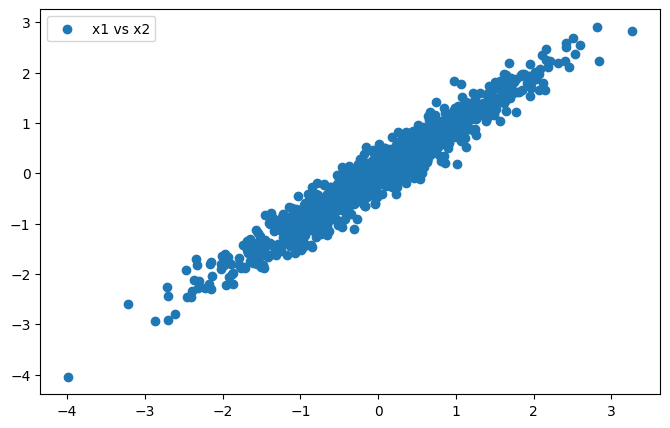

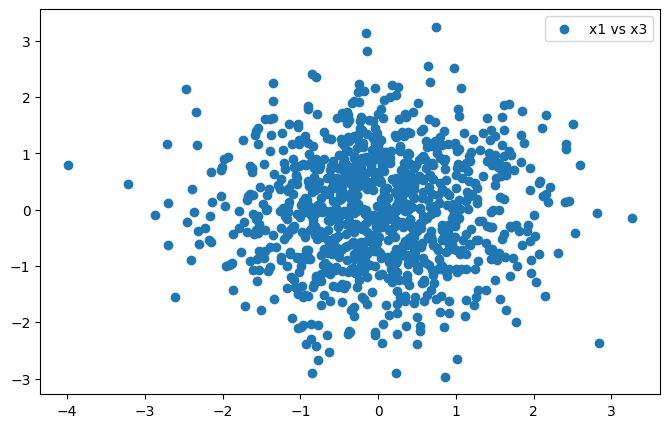

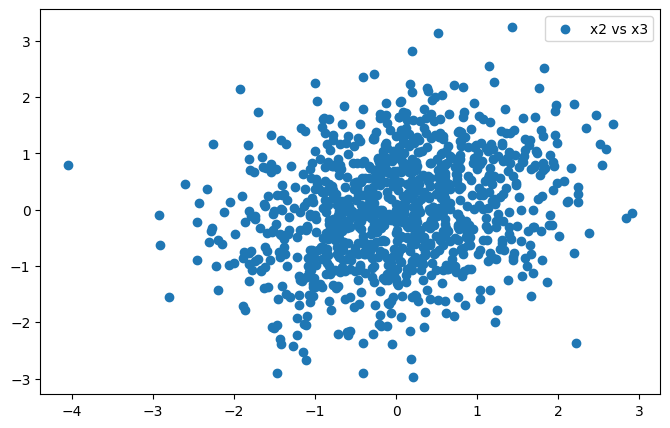

In [ ]:
plt.scatter(datos_normalizados[:,0], datos_normalizados[:,1], label="x1 vs x2")
plt.legend()
plt.show()

plt.scatter(datos_normalizados[:,0], datos_normalizados[:,2], label="x1 vs x3")
plt.legend()
plt.show()

plt.scatter(datos_normalizados[:,1], datos_normalizados[:,2], label="x2 vs x3")
plt.legend()

3. ### Calcular la matriz de covarianza, y hallar sus autovalores y autovectores.


In [ ]:
cant_datos = datos_normalizados.shape[0]

matriz_covarianza = np.dot( np.transpose(datos_normalizados), datos_normalizados) / cant_datos
print("Matriz de covarianza:\n", matriz_covarianza)
# ¿están bien las dimensiones?


# eigh es especial para matrices diagonalizables por autovectores ortogonales
# devuelve autovalores en orden creciente: NO nos conviene para componentes principales
e = np.linalg.eigh(matriz_covarianza)
autovalores = e[0]
U = e[1]
print("\nAutovalores de la matriz de covarianza:", autovalores)
print("\nMatriz de autovectores de la matriz de covarianza:\n", U)

#ordenamos de mayor a menor: porque así lo necesita componentes principales
autovalores = np.flip(autovalores)
U = np.fliplr(U) #invierte el orden de las columnas
print("\nAutovalores ordenados decrecientes:\n", autovalores)
print("\nMatriz de autovectores ordenados de acuerdo a autovalores decrecientes:\n", U)

Matriz de covarianza:
 [[1.         0.9672597  0.02451547]
 [0.9672597  1.         0.23878603]
 [0.02451547 0.23878603 1.        ]]

Autovalores de la matriz de covarianza: [0.0091509  0.98859652 2.00225258]

Matriz de autovectores de la matriz de covarianza:
 [[-0.68827243 -0.23937437 -0.68482186]
 [ 0.70895661 -0.02178014 -0.7049157 ]
 [-0.15382324  0.97068303 -0.18469671]]

Autovalores ordenados decrecientes:
 [2.00225258 0.98859652 0.0091509 ]

Matriz de autovectores ordenados de acuerdo a autovalores decrecientes:
 [[-0.68482186 -0.23937437 -0.68827243]
 [-0.7049157  -0.02178014  0.70895661]
 [-0.18469671  0.97068303 -0.15382324]]


4. ### Hallar las componentes principales: dar la fórmula para los scores, es decir la fórmula que permite transformar el dato original al mismo dato pero escrito en las coordenadas de los ejes dados por las componentes principales.

In [ ]:
print("\nMatriz de autovectores ordenados de acuerdo a autovalores decrecientes:\n", U)

# a las columnas de U típicamente se las llama loadings o cargas.


Matriz de autovectores ordenados de acuerdo a autovalores decrecientes:
 [[-0.68482186 -0.23937437 -0.68827243]
 [-0.7049157  -0.02178014  0.70895661]
 [-0.18469671  0.97068303 -0.15382324]]


$Z = XU$

$(z_1, z_2, z_3) = (x_1, x_2, x_3)U$

$z_1 = -0.68482186x_1 -0.7049157x_2 -0.18469671x_3$

$z_2 = $ ídem con columna 2 de $U$

$z_3 = $ ídem con columna 3 de $U$

5. ### Hallar los scores, es decir la nueva tabla de datos correspondiente a los datos pero escritos en los nuevos ejes dados por las componentes principales.

In [ ]:
Z = np.dot(datos_normalizados, U)
print("Scores: nueva tabla de datos:\n", Z)

# la fila 1 proviene de hacer la cuenta del ítem anterior para el primer dato
# la fila 2 proviene de hacer la cuenta del ítem anterior para el segundo dato
# etc

# por ejemplos los scores para el dato (inventado) (x1, x2, x3) = (0.4, 3, 1.258) es
print("\nScores para el dato (inventado) (x1, x2, x3) = (0.4, 3, 1.258):", np.dot( np.array([0.4, 3, 1.258]), U))

Scores: nueva tabla de datos:
 [[-0.66478432  1.0034238  -0.08764166]
 [-0.03150378 -1.96537458 -0.00742951]
 [-0.80249366 -0.549539   -0.0068847 ]
 ...
 [-1.20180004 -0.49050301  0.05810923]
 [-1.39194638  0.68894325 -0.00825467]
 [-0.32890916 -0.02877689 -0.01077764]]

Scores para el dato (inventado) (x1, x2, x3) = (0.4, 3, 1.258): [-2.62102431  1.06002909  1.65805124]


6. ### Utilizando regresión lineal (cuadrados mínimos) decidir en cuáles de las componentes principales está mayormente representada la información de los datos.


In [ ]:
def cuad_min(x,y):    # Cuadrados minimos con polyfit
    reg_lin = Poly.fit(x,y,1)
    vals_y_reg_lin = reg_lin(x)
    # R^2 para datos de media cero
    R2 = np.linalg.norm(vals_y_reg_lin, 2)**2 / np.linalg.norm(y, 2)**2
    return vals_y_reg_lin, R2

p, R2 = cuad_min(Z[:,0], datos_normalizados[:,0])
print("R2 de x1* en función de z1:", R2)
p, R2 = cuad_min(Z[:,0], datos_normalizados[:,1])
print("R2 de x2* en función de z1:", R2)
p, R2 = cuad_min(Z[:,0], datos_normalizados[:,2])
print("R2 de x3* en función de z1:", R2)

p, R2 = cuad_min(Z[:,1], datos_normalizados[:,0])
print("\nR2 de x1* en función de z2:", R2)
p, R2 = cuad_min(Z[:,1], datos_normalizados[:,1])
print("R2 de x2* en función de z2:", R2)
p, R2 = cuad_min(Z[:,1], datos_normalizados[:,2])
print("R2 de x3* en función de z2:", R2)

p, R2 = cuad_min(Z[:,2], datos_normalizados[:,0])
print("\nR2 de x1* en función de z3:", R2)
p, R2 = cuad_min(Z[:,2], datos_normalizados[:,1])
print("R2 de x2* en función de z3:", R2)
p, R2 = cuad_min(Z[:,2], datos_normalizados[:,2])
print("R2 de x3* en función de z3:", R2)


R2 de x1* en función de z1: 0.939018379163669
R2 de x2* en función de z1: 0.9949316150669975
R2 de x3* en función de z1: 0.06830258904915631

R2 de x1* en función de z2: 0.05664666667872351
R2 de x2* en función de z2: 0.0004689647871088239
R2 de x3* en función de z2: 0.9314808861459457

R2 de x1* en función de z3: 0.004334954157607511
R2 de x2* en función de z3: 0.004599420145892823
R2 de x3* en función de z3: 0.00021652480489762392


7. ### Indicar la proporción de variabilidad explicada por cada componente principal.


In [ ]:
varianza_total = sum(autovalores)
for i in range(len(autovalores)):
    prop_varianza_explicada_i = autovalores[i]/varianza_total
    print('Proporción de variabilidad explicada por la CP',i,'es',round(100*prop_varianza_explicada_i,2),'%')

Proporción de variabilidad explicada por la CP 0 es 66.74 %
Proporción de variabilidad explicada por la CP 1 es 32.95 %
Proporción de variabilidad explicada por la CP 2 es 0.31 %


8. ### Hallar la cantidad de componentes principales que explican al menos el 99.5% de la variabilidad acumulada.


In [ ]:
varianza_total = sum(autovalores)  #suma de todos los autovalores

umbral = 0.995 #tener el 99.5% de la varianza total
i=0
prop_varianza_explicada_parcial = autovalores[0]/varianza_total
while prop_varianza_explicada_parcial < umbral:
      i = i+1
      prop_varianza_explicada_parcial = prop_varianza_explicada_parcial + autovalores[i]/varianza_total

print("Necesito las primeras",i+1,"componentes principales")
print("La proporción de varianza explicada por esas CPs es:", prop_varianza_explicada_parcial)

Necesito las primeras 2 componentes principales
La proporción de varianza explicada por esas CPs es: 0.9969497002972005


9. ### Hallar los scores para la cantidad de componentes principales averiguadas en el ítem anterior, es decir los nuevos datos truncados provenientes de la reducción de la dimensión del ítem anterior.


In [ ]:
Z_truncado = Z[:, 0:2] #las primeras dos columnas
print("Los scores truncados\n", Z_truncado)
# las componentes principales z1 y z2 quedan en las columnas

Los scores truncados
 [[-0.66478432  1.0034238 ]
 [-0.03150378 -1.96537458]
 [-0.80249366 -0.549539  ]
 ...
 [-1.20180004 -0.49050301]
 [-1.39194638  0.68894325]
 [-0.32890916 -0.02877689]]


10. ### Graficar los nuevos datos truncados.


(-7.0, 7.0)

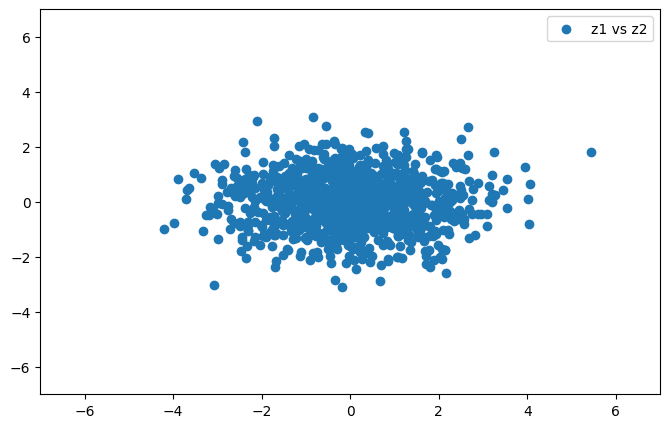

In [ ]:
plt.scatter(Z_truncado[:,0], Z_truncado[:,1], label= "z1 vs z2")
plt.legend()

# para que se vea mejor
# observar la despersión en cada eje, y relacionarlo con la variabilidad explicada.
l = 7
plt.xlim(-l,l)
plt.ylim(-l,l)

11. ### YAPA: datos truncados graficados en el espacio original, es decir proyectando sobre las componentes principales

$ Z = XU$

$ X = ZU^t$

(-7.0, 7.0)

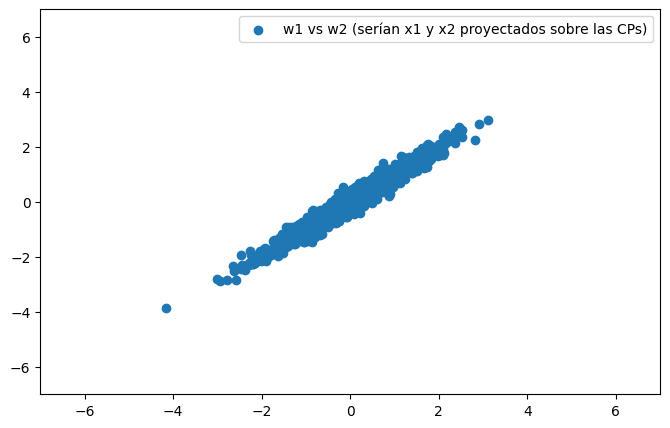

In [ ]:
U_truncada = U[:, 0:2]

W = np.dot(Z_truncado, np.transpose(U_truncada))

plt.scatter(W[:,0], W[:,1], label= "w1 vs w2 (serían x1 y x2 proyectados sobre las CPs)")
plt.legend()
l = 7
plt.xlim(-l,l)
plt.ylim(-l,l)

---
# Todo lo anterior con `scikit-learn`

In [ ]:
##### Con scikit-learn

from sklearn.preprocessing import StandardScaler
# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler
from sklearn.decomposition import PCA
# https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html


# Estandarizo datos
scaler = StandardScaler()
datos_normalizados = scaler.fit_transform(datos)
print("Datos normalizados por scikit-learn:\n",datos_normalizados)

# Matriz de covarianza
matriz_covarianza = np.cov(datos_normalizados.T, bias=True)
print("Matriz de covarianza:\n", matriz_covarianza)

# Hago PCA
pca = PCA(n_components=3)
pca.fit(datos_normalizados)

# componentes principales (autovectores de la matriz de covarianza)
print("CPs (autovectores de la matriz de covarianza):\n", pca.components_.T)
Z = pca.transform(datos_normalizados) #scores
# print(Z)

# varianza y proporción de cada CP
print("Varianza por cada CP (autovalores de la matriz de covarianza):", pca.explained_variance_)
print("Proporción de varianza explicada por cada CP:", pca.explained_variance_ratio_)


# me quedo con las CPs necesarias para tener el 99.5% de la varianza total
umbral = 0.995
prop_varianza_explicada_parcial = pca.explained_variance_ratio_[0]
i=0
while prop_varianza_explicada_parcial < umbral:
      i = i+1
      prop_varianza_explicada_parcial = prop_varianza_explicada_parcial + pca.explained_variance_ratio_[i]


print("Necesito las primeras",i+1,"componentes principales")
print("La proporción de varianza explicada por esas CPs es:", prop_varianza_explicada_parcial)


# Me quedo con la cantidad de CPs que me sirven y proyecto los datos
Z_truncado = Z[:, 0:2] #las primeras dos columnas (antes averigüé que necesito 2 para llegar al 99.5% de varianza explicada)
print("Los scores truncados\n", Z_truncado)
# las componentes principales z1 y z2 quedan en las columnas

Datos normalizados por scikit-learn:
 [[ 0.27538624  0.38462806  1.11027125]
 [ 0.4971483   0.05974644 -1.90079427]
 [ 0.6858493   0.57277846 -0.38415122]
 ...
 [ 0.90043781  0.89904787 -0.26309299]
 [ 0.79400141  0.96034738  0.92710319]
 [ 0.23955058  0.22483912  0.03447305]]
Matriz de covarianza:
 [[1.         0.9672597  0.02451547]
 [0.9672597  1.         0.23878603]
 [0.02451547 0.23878603 1.        ]]
CPs (autovectores de la matriz de covarianza):
 [[ 0.68482186 -0.23937437 -0.68827243]
 [ 0.7049157  -0.02178014  0.70895661]
 [ 0.18469671  0.97068303 -0.15382324]]
Varianza por cada CP (autovalores de la matriz de covarianza): [2.00425684 0.9895861  0.00916006]
Proporción de varianza explicada por cada CP: [0.66741753 0.32953217 0.0030503 ]
Necesito las primeras 2 componentes principales
La proporción de varianza explicada por esas CPs es: 0.9969497002972005
Los scores truncados
 [[ 0.66478432  1.0034238 ]
 [ 0.03150378 -1.96537458]
 [ 0.80249366 -0.549539  ]
 ...
 [ 1.20180004 -0.